<a href="https://colab.research.google.com/github/sayyida01/sayyidana/blob/main/ForumSayyida02_DataEngineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scatter MedInc vs MedHouseVal dengan regresi non-linear

In [1]:
from google.colab import files
uploaded = files.upload()

Saving housing.csv to housing.csv


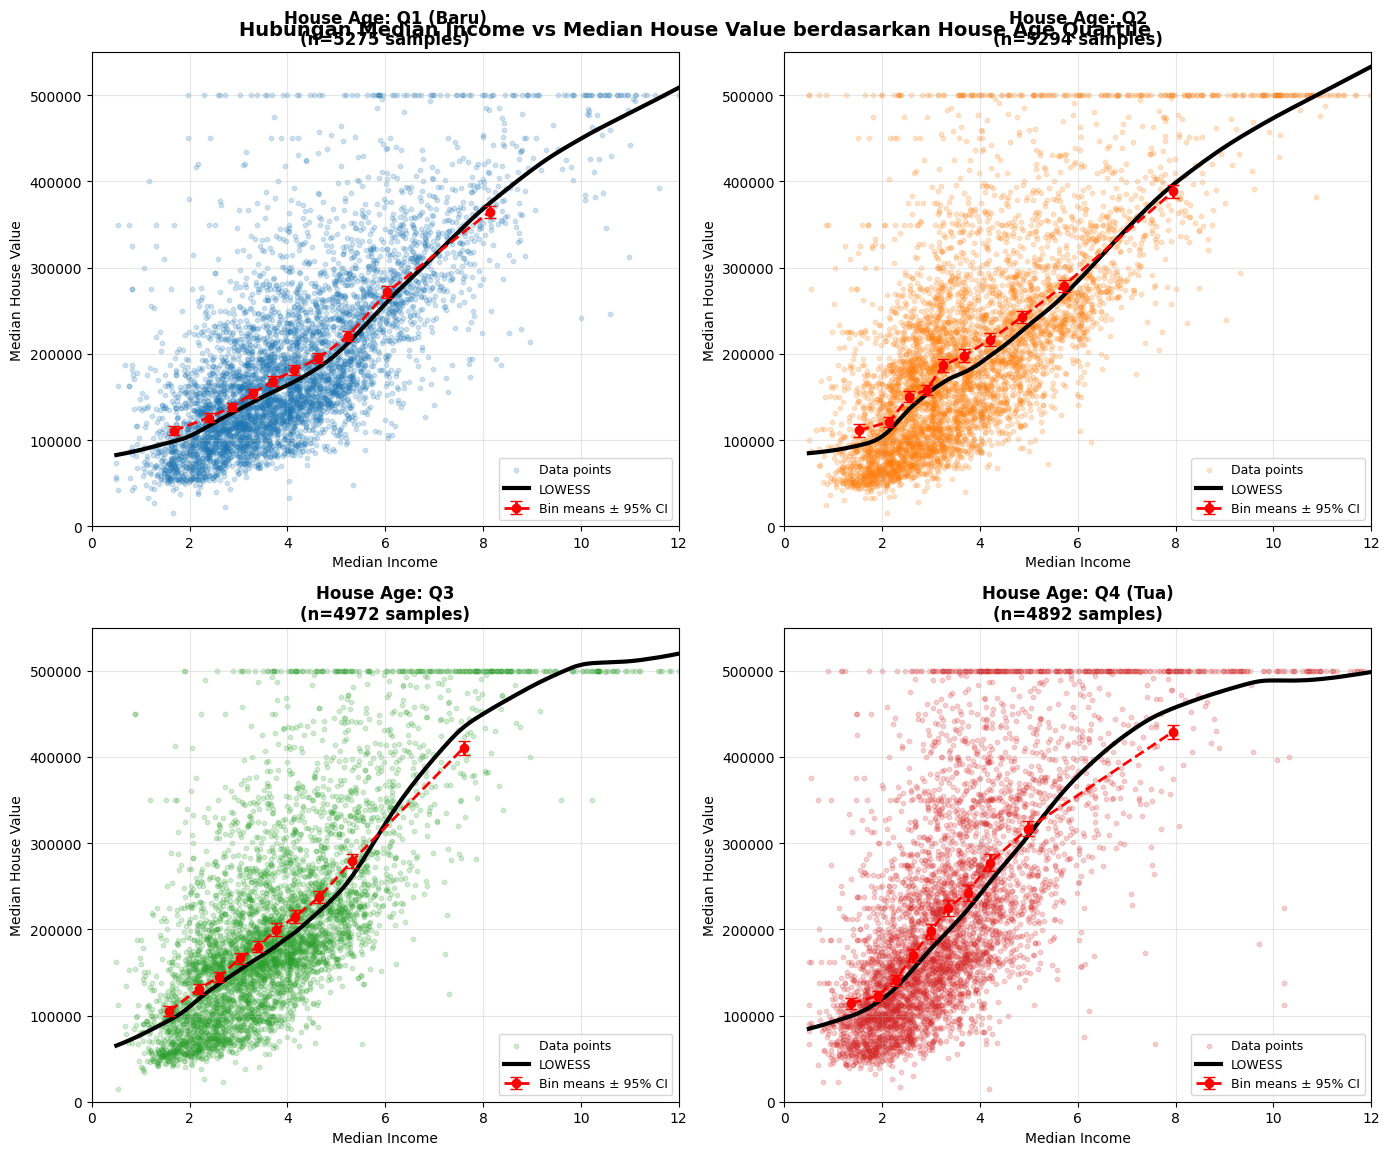

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess

# Load data
data = pd.read_csv('housing.csv')

# Handle missing values
data = data.dropna()

# 1. Bagi HouseAge menjadi 4 kuartil
data['HouseAge_quartile'] = pd.qcut(data['housing_median_age'], q=4, labels=['Q1 (Baru)', 'Q2', 'Q3', 'Q4 (Tua)'])

# Buat figure dengan 4 subplot
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

# Warna berbeda tiap kuartil
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, quartile in enumerate(data['HouseAge_quartile'].cat.categories):
    ax = axes[i]
    subset = data[data['HouseAge_quartile'] == quartile]

    # Scatter plot dengan transparansi
    ax.scatter(subset['median_income'], subset['median_house_value'],
               alpha=0.2, color=colors[i], s=10, label='Data points')

    # LOWESS smoothing
    lowess_result = lowess(subset['median_house_value'], subset['median_income'], frac=0.3)
    ax.plot(lowess_result[:, 0], lowess_result[:, 1],
            color='black', linewidth=3, label='LOWESS', zorder=5)

    # Bin means dengan 10 decile - cara yang lebih robust
    subset_copy = subset.copy()

    # Bikin bin dengan handle duplicates
    try:
        subset_copy['income_bin'] = pd.qcut(subset_copy['median_income'], q=10, duplicates='drop')
    except:
        # Fallback kalo masih error
        subset_copy['income_bin'] = pd.cut(subset_copy['median_income'], bins=10)

    # Group by dan aggregate
    bin_means = subset_copy.groupby('income_bin', observed=False).agg(
        mean_income=('median_income', 'mean'),
        mean_value=('median_house_value', 'mean'),
        se_value=('median_house_value', 'sem'),
        count=('median_house_value', 'count')
    ).reset_index()

    # Filter out bins dengan data terlalu sedikit
    bin_means = bin_means[bin_means['count'] >= 5]

    # Plot error bar hanya jika ada data yang valid
    if len(bin_means) > 0:
        ax.errorbar(bin_means['mean_income'], bin_means['mean_value'],
                   yerr=bin_means['se_value'] * 1.96, fmt='o--',
                   color='red', linewidth=2, markersize=6, capsize=4,
                   label='Bin means ± 95% CI', zorder=6)

    ax.set_title(f'House Age: {quartile}\n(n={len(subset)} samples)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Median Income', fontsize=10)
    ax.set_ylabel('Median House Value', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Set limit yang reasonable
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 550000)

plt.suptitle('Hubungan Median Income vs Median House Value berdasarkan House Age Quartile',
             fontsize=14, fontweight='bold', y=0.95)
plt.tight_layout()
plt.show()